# Task 1 Setting the baseline

## Imports

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import missingno as msno
import seaborn as sns

In [10]:
def cMSE(y, y_hat, c):
    err = y-y_hat
    err = (1-c)*err**2 + c*np.maximum(0,err)**2
    return np.sum(err)/err.shape[0]
    
def plot_y_yhat(y_test, y_pred, plot_title="plot"):
    label = 'SurvivalTime'
    MAX = 500

    if len(y_test) > MAX:
        idx = np.random.choice(len(y_test), MAX, replace=False)
    else:
        idx = np.arange(len(y_test))

    plt.figure(figsize=(6, 6))
    x0 = np.min(y_test[idx])
    x1 = np.max(y_test[idx])
    plt.scatter(y_test[idx], y_pred[idx], alpha=0.7)
    plt.xlabel(f'True {label}')
    plt.ylabel(f'Predicted {label}')
    plt.plot([x0, x1], [x0, x1], color='red')
    plt.title(f'True vs Predicted {label}')
    plt.axis('square')
    plt.savefig(plot_title + '.pdf')
    plt.show()
    
def save_predictions(predictions, path):
    df = pd.DataFrame({
        'id': range(len(predictions)),
        '0': predictions
    })
    
    df.to_csv(path, index=False)
    
def model_metrics(y_true, y_pred):
    error = y_true - y_pred
    metrics = {
        'Max Error': np.max(np.abs(error)),
        'Min Error': np.min(np.abs(error)),
        'Mean Error': np.mean(np.abs(error)),
        'Std of Error': np.std(error)
    }
    return metrics
    
def evaluate_model(X, y, c, model, show_cmse=True, show_plot=False):
    X_train, X_test, y_train, y_test, c_train, c_test = train_test_split(X, y, c, test_size=0.2, random_state=30)
    
    y_pred_cv = cross_val_predict(model, X_train, y_train, cv=10)
    cMSE_cv = cMSE(y_train, y_pred_cv, c_train)
    
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_test)
    cMSE_test = cMSE(y_test, y_pred, c_test)
    
    if show_cmse:
        print(f"CV cMSE: {cMSE_cv}")
        print(f"Test cMSE: {cMSE_test}")
    
    if show_plot:
        plot_y_yhat(y_test, y_pred, plot_title="y_yhat_plot")
    
    return model, cMSE_cv, cMSE_test, model_metrics(y_test, y_pred)

### Visualizations of missing data and correlation

In [9]:
msno.bar(df)

In [6]:
msno.heatmap(df)

In [8]:
msno.dendrogram(df)

### Drop the columns containing the features with missing data and the censored data points, or missing survival time.

### Check the pairplot between the remaining features and the target variable

In [11]:
sns.pairplot(df, kind="hist")

### Define the matrix X with the features as columns and examples as rows, and y as a vector with the Survival Time.

In [17]:
X = df.drop(columns=['SurvivalTime', 'Censored'])
y = df['SurvivalTime']
c = df['Censored']

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"c shape: {c.shape}")

X = np.array(X)
y = np.array(y)
c = np.array(c)

### Most data efficient process for the split is using Cross-Validation

## Task 1.2 Learn the baseline model

### Data split; Cross-validation; Linear regression

In [18]:
linear_reg = make_pipeline(StandardScaler(), LinearRegression())
linear_reg, _ , _, _ = evaluate_model(X, y, c, linear_reg, show_plot=True)

### Submission

Load Kaggle dataset and process it as needed

In [46]:
X_kaggle_df = pd.read_csv('./mlNOVA/test_data.csv')
X_kaggle_df.drop(columns=['id'], inplace=True)
X_kaggle_df.drop(columns=['GeneticRisk', 'ComorbidityIndex', 'TreatmentResponse'], inplace=True)
X_kaggle_df.head()

Save prediction

In [47]:
y_baseline_pred = linear_reg.predict(X_kaggle_df)
save_predictions(y_baseline_pred, './submissions/baseline-submission-02.csv')

## Task 1.3 Learn with the cMSE

### Gradient descent implementation

Took inspiration from this implementation of gradient descent: https://www.geeksforgeeks.org/how-to-implement-a-gradient-descent-in-python-to-find-a-local-minimum/

In [30]:
def gradient_descent(X, y, c, learning_rate=0.01, iterations=1000, threshold=1e-6, regularization=None, alpha=0.01):
    N, M = X.shape
    weights = np.zeros(M)
    bias = 0.0
    losses = []
    previous_loss = None

    for i in range(iterations):
        y_hat = X @ weights + bias

        sub_expression = (1 - c) * (y - y_hat) + c * np.maximum(0, y - y_hat)
        gradient = (X.T @ (-2 * sub_expression)) / N
        bias_gradient = np.mean(-2 * sub_expression)

        if regularization == 'ridge':
            gradient += 2 * alpha * weights
        elif regularization == 'lasso':
            gradient += alpha * np.sign(weights)

        weights -= learning_rate * gradient
        bias -= learning_rate * bias_gradient

        regularization_term = 0
        if regularization == 'ridge':
            regularization_term = alpha * np.sum(weights**2)
        elif regularization == 'lasso':
            regularization_term = alpha * np.sum(np.abs(weights))
        
        current_loss = cMSE(y, y_hat, c) + regularization_term
        
        if previous_loss and abs(previous_loss - current_loss) <= threshold:
            break
        
        previous_loss = current_loss
        losses.append(current_loss)

    return weights, bias, losses

### Run Gradient Descent and evaluate it

##### Pre-processing

In [23]:
df = pd.read_csv('./mlNOVA/train_data.csv')
df.drop(columns=['id'], inplace=True)
df.drop(columns=['GeneticRisk', 'ComorbidityIndex', 'TreatmentResponse'], inplace=True)
df = df.dropna(subset=['SurvivalTime'])

In [24]:
X = df.drop(columns=['SurvivalTime', 'Censored'])
y = df['SurvivalTime']
c = df['Censored']

print(f"Feature matrix X shape: {X.shape}")
print(f"Target vector y shape: {y.shape}")
print(f"Censored vector c shape: {c.shape}")

X = np.array(X)
y = np.array(y)
c = np.array(c)

Feature matrix X shape: (240, 4)
Target vector y shape: (240,)
Censored vector c shape: (240,)


In [25]:
X_train, X_test, y_train, y_test, c_train, c_test = train_test_split(X, y, c, test_size=0.2, random_state=30)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#### Experiment with regularization

##### No regularization

Training cMSE: 3.2812469296735487
Test cMSE: 2.8541970764514395


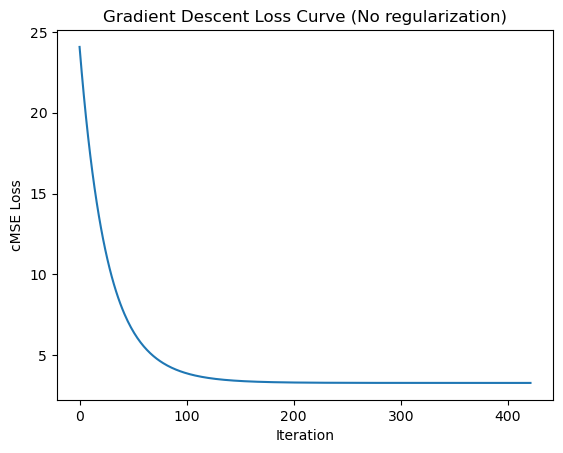

array([0.0464564 , 0.09986771, 0.06093597, 0.65540196])

In [32]:
weights, bias, losses = gradient_descent(
    X_train_scaled, y_train, c_train, learning_rate=0.01, iterations=1000, regularization=None
)

y_pred_test = X_test_scaled @ weights + bias

cMSE_training = losses[-1]
cMSE_test = cMSE(y_test, y_pred_test, c_test)

print(f"Training cMSE: {cMSE_training}")
print(f"Test cMSE: {cMSE_test}")

plt.plot(losses)
plt.xlabel("Iteration")
plt.ylabel("cMSE Loss")
plt.title("Gradient Descent Loss Curve (No regularization)")
plt.show()

weights

##### Ridge

Training cMSE: 3.2812469296735487
Test cMSE: 2.933643083454404


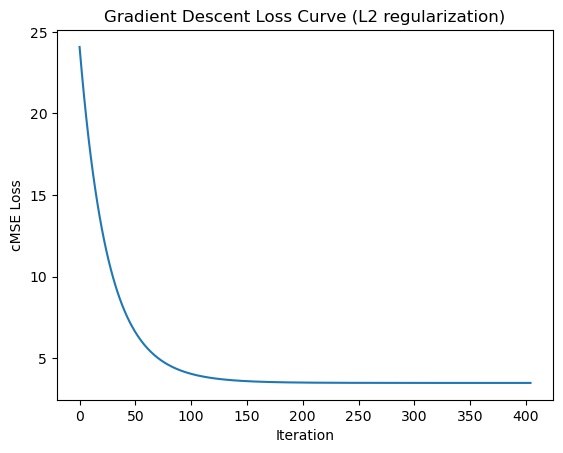

array([0.03896513, 0.03483363, 0.03307629, 0.28804721])

In [46]:
weights_ridge, bias_ridge, losses_ridge = gradient_descent(
    X_train_scaled, y_train, c_train, learning_rate=0.01, iterations=1000, regularization='ridge', alpha=1.0
)

y_pred_test = X_test_scaled @ weights_ridge + bias_ridge

cMSE_training = losses[-1]
cMSE_test = cMSE(y_test, y_pred_test, c_test)

print(f"Training cMSE: {cMSE_training}")
print(f"Test cMSE: {cMSE_test}")

plt.plot(losses_ridge)
plt.xlabel("Iteration")
plt.ylabel("cMSE Loss")
plt.title("Gradient Descent Loss Curve (L2 regularization)")
plt.show()

weights_ridge

##### Lasso

Training cMSE: 3.2812469296735487
Test cMSE: 3.2490673519910263


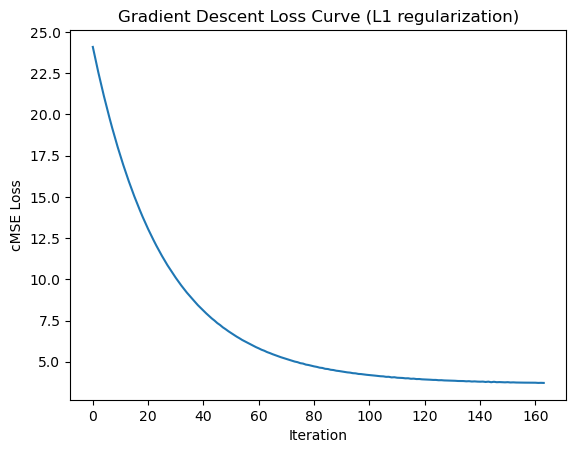

array([-0.00315801, -0.00865783,  0.00406517,  0.01549574])

In [44]:
weights_lasso, bias_lasso, losses_lasso = gradient_descent(
    X_train_scaled, y_train, c_train, learning_rate=0.01, iterations=1000, regularization='lasso', alpha=1.0
)

y_pred_test = X_test_scaled @ weights_lasso + bias_lasso

cMSE_training = losses[-1]
cMSE_test = cMSE(y_test, y_pred_test, c_test)

print(f"Training cMSE: {cMSE_training}")
print(f"Test cMSE: {cMSE_test}")

plt.plot(losses_lasso)
plt.xlabel("Iteration")
plt.ylabel("cMSE Loss")
plt.title("Gradient Descent Loss Curve (L1 regularization)")
plt.show()

weights_lasso

### Submission

#### Load kaggle dataset

In [36]:
X_kaggle_df = pd.read_csv('./mlNOVA/test_data.csv')
X_kaggle_df.drop(columns=['id'], inplace=True)
X_kaggle_df.drop(columns=['GeneticRisk', 'ComorbidityIndex', 'TreatmentResponse'], inplace=True)
X_kaggle_df = np.array(X_kaggle_df)

X_kaggle_df_scaled = scaler.transform(X_kaggle_df)

#### Save prediction

In [58]:
y_gradient_pred = X_kaggle_df_scaled @ weights + bias
save_predictions(y_gradient_pred, './submissions/cMSE-baseline-submission-03.csv')